In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
import os

project_folder = "/content/drive/MyDrive/MVJ_Internship/Project3/Day17_Regression"

raw_folder = os.path.join(project_folder, "data", "raw")
processed_folder = os.path.join(project_folder, "data", "processed")

print("Project folder:", project_folder)
print("Raw data folder:", raw_folder)
print("Processed data folder:", processed_folder)

Project folder: /content/drive/MyDrive/MVJ_Internship/Project3/Day17_Regression
Raw data folder: /content/drive/MyDrive/MVJ_Internship/Project3/Day17_Regression/data/raw
Processed data folder: /content/drive/MyDrive/MVJ_Internship/Project3/Day17_Regression/data/processed


In [5]:
#verify the folders and inspect the raw dataset

print("Raw folder exists:", os.path.exists(raw_folder))
print("Processed folder exists:", os.path.exists(processed_folder))

print("\nFiles inside raw folder:")

for file in os.listdir(raw_folder):
    print(file)

Raw folder exists: True
Processed folder exists: False

Files inside raw folder:
Bengaluru_House_Data.csv


In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [7]:
#load the dataset

# Identify CSV files inside the raw folder

csv_files = [
    file for file in os.listdir(raw_folder)
    if file.lower().endswith(".csv")
]

print("CSV files found:", csv_files)

CSV files found: ['Bengaluru_House_Data.csv']


In [8]:
# Load the dataset

if len(csv_files) != 1:
    raise ValueError(
        f"Expected exactly one CSV file, but found {len(csv_files)}. "
        "Please check the raw folder."
    )

file_path = os.path.join(raw_folder, csv_files[0])

df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (13320, 9)


In [9]:
#preview of the dataset

df.head()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00


In [10]:
df.tail()

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.0
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.0
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.0
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.0
13319,Super built-up Area,Ready To Move,Doddathoguru,1 BHK,NaN,550,1.0,1.0,17.0


In [11]:
#understand the datasest structure

# Display column names

print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Column names:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [12]:
# Count missing values in each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (missing_values / len(df)) * 100
})

missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

,Missing Values,Missing Percentage
society,5502,41.306306
balcony,609,4.572072
bath,73,0.548048
size,16,0.120120
location,1,0.007508
area_type,0,0.000000
availability,0,0.000000
total_sqft,0,0.000000
price,0,0.000000


In [13]:
# Count duplicate rows

duplicate_count = df.duplicated().sum()

print("Number of duplicate rows:", duplicate_count)

Number of duplicate rows: 529


In [14]:
# Statistical summary of numerical columns

df.describe().T

,count,mean,std,min,25%,50%,75%,max
bath,13247.0,2.692610,1.341458,1.0,2.0,2.0,3.0,40.0
balcony,12711.0,1.584376,0.817263,0.0,1.0,2.0,2.0,3.0
price,13320.0,112.565627,148.971674,8.0,50.0,72.0,120.0,3600.0


In [15]:
#data preparation and cleaning

# Create a separate working copy of the original dataset

df_clean = df.copy()

print("Working copy created successfully!")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

Working copy created successfully!
Original dataset shape: (13320, 9)
Working dataset shape: (13320, 9)


In [16]:
#standardise column names

# Clean and standardize column names

df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Updated column names:")
print(df_clean.columns.tolist())

Updated column names:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price']


In [17]:
# Identify numerical columns

numerical_columns = df_clean.select_dtypes(
    include=np.number
).columns.tolist()

# Identify categorical columns

categorical_columns = df_clean.select_dtypes(
    include="object"
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['bath', 'balcony', 'price']

Categorical columns:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft']


In [18]:
## Check unique values in categorical columns

for column in categorical_columns:
    print(f"\nColumn: {column}")
    print("Unique values:", df_clean[column].nunique())
    print("Sample values:")
    print(df_clean[column].dropna().unique()[:15])


Column: area_type
Unique values: 4
Sample values:
['Super built-up  Area' 'Plot  Area' 'Built-up  Area' 'Carpet  Area']

Column: availability
Unique values: 81
Sample values:
['19-Dec' 'Ready To Move' '18-May' '18-Feb' '18-Nov' '20-Dec' '17-Oct'
 '21-Dec' '19-Sep' '20-Sep' '18-Mar' '20-Feb' '18-Apr' '20-Aug' '18-Oct']

Column: location
Unique values: 1305
Sample values:
['Electronic City Phase II' 'Chikka Tirupathi' 'Uttarahalli'
 'Lingadheeranahalli' 'Kothanur' 'Whitefield' 'Old Airport Road'
 'Rajaji Nagar' 'Marathahalli' 'Gandhi Bazar' '7th Phase JP Nagar'
 'Gottigere' 'Sarjapur' 'Mysore Road' 'Bisuvanahalli']

Column: size
Unique values: 31
Sample values:
['2 BHK' '4 Bedroom' '3 BHK' '4 BHK' '6 Bedroom' '3 Bedroom' '1 BHK'
 '1 RK' '1 Bedroom' '8 Bedroom' '2 Bedroom' '7 Bedroom' '5 BHK' '7 BHK'
 '6 BHK']

Column: society
Unique values: 2688
Sample values:
['Coomee ' 'Theanmp' 'Soiewre' 'DuenaTa' 'Jaades ' 'Brway G' 'Prrry M'
 'Shncyes' 'Skityer' 'PrntaEn' 'Prityel' 'GrrvaGr' 'PeBay

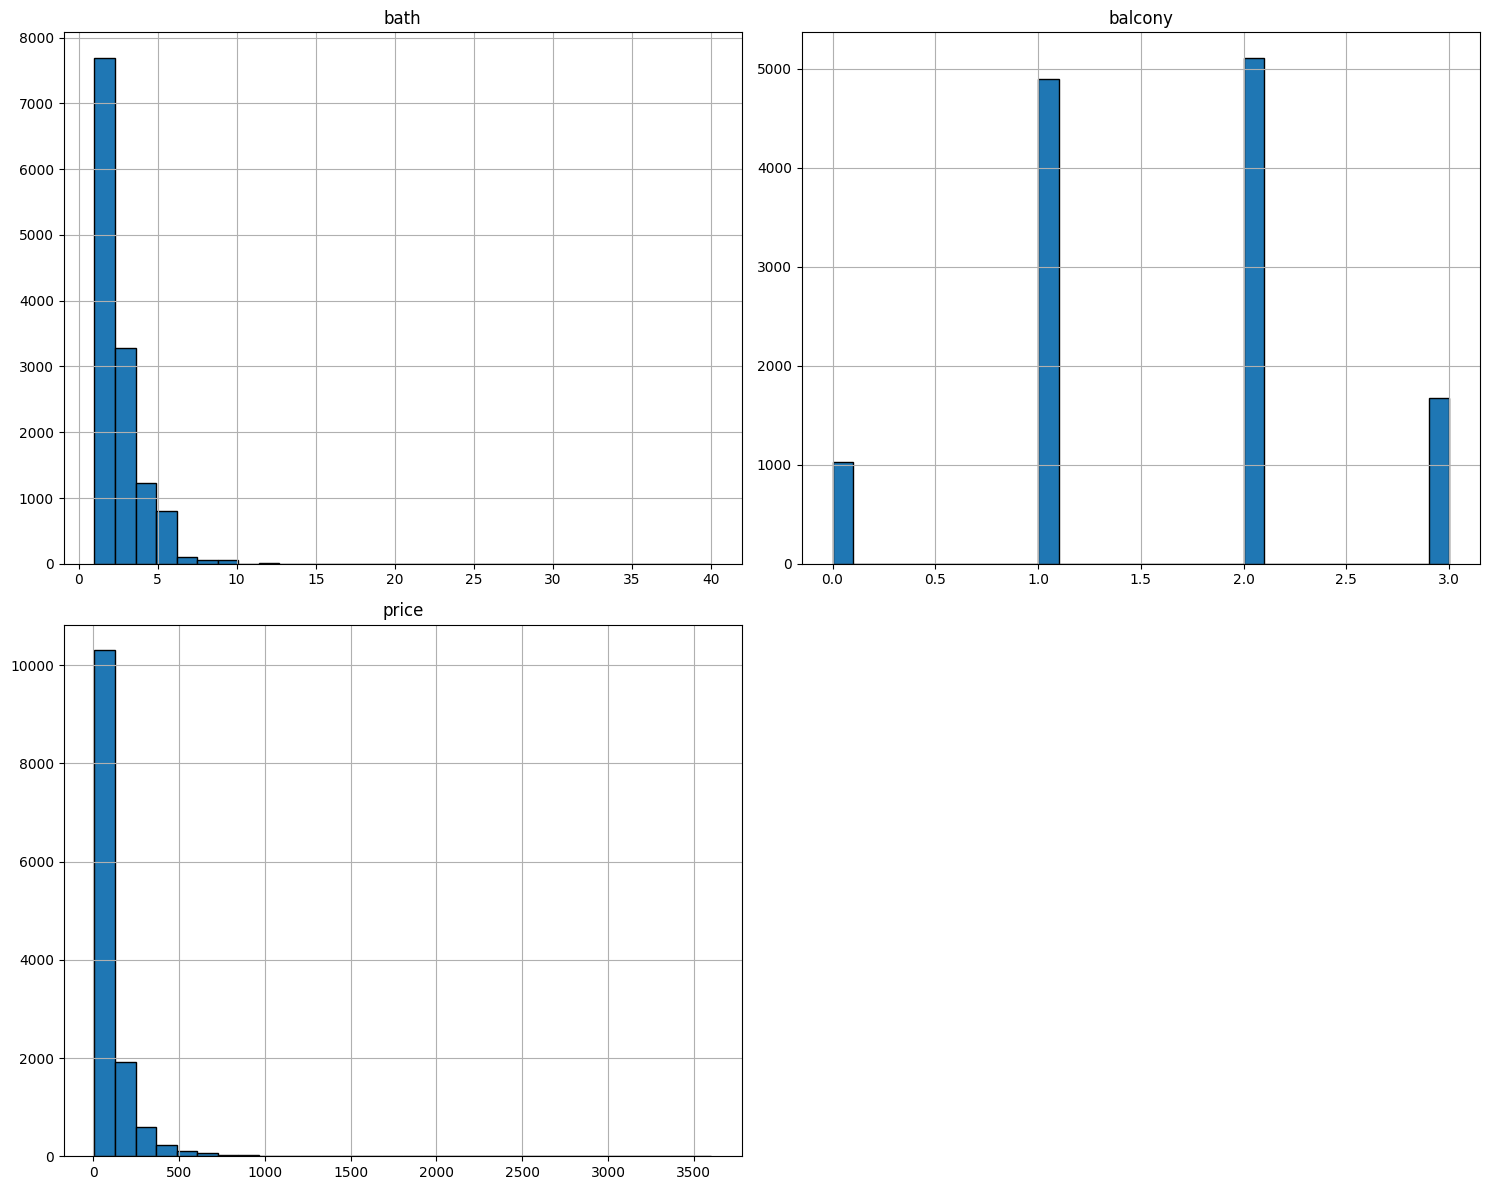

In [19]:
#check numerical data distributions

# Generate histograms for numerical columns

df_clean[numerical_columns].hist(
    figsize=(15, 12),
    bins=30,
    edgecolor="black"
)

plt.tight_layout()
plt.show()


DATA CLEANING

In [20]:
# Display columns with missing values

missing_summary = pd.DataFrame({
    "Missing_Count": df_clean.isnull().sum(),
    "Missing_Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_summary = missing_summary[
    missing_summary["Missing_Count"] > 0
].sort_values(by="Missing_Count", ascending=False)

display(missing_summary)

,Missing_Count,Missing_Percentage
society,5502,41.31
balcony,609,4.57
bath,73,0.55
size,16,0.12
location,1,0.01


In [21]:
# Fill missing categorical values

if "location" in df_clean.columns:
    df_clean["location"] = df_clean["location"].fillna("Unknown")

# Fill missing numerical values with median

for column in ["bath", "balcony"]:
    if column in df_clean.columns:
        df_clean[column] = df_clean[column].fillna(
            df_clean[column].median()
        )

print("Missing-value treatment completed.")

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

Missing-value treatment completed.

Remaining missing values:
area_type          0
availability       0
location           0
size              16
society         5502
total_sqft         0
bath               0
balcony            0
price              0
dtype: int64


In [22]:
# Check duplicates before removal

print("Duplicates before cleaning:", df_clean.duplicated().sum())

# Remove exact duplicate rows

df_clean = df_clean.drop_duplicates().copy()

print("Duplicates after cleaning:", df_clean.duplicated().sum())

print("Updated dataset shape:", df_clean.shape)

Duplicates before cleaning: 530
Duplicates after cleaning: 0
Updated dataset shape: (12790, 9)


In [23]:
#extract the numerical bedroom count into a new column.

# Extract bedroom count from size

if "size" in df_clean.columns:

    df_clean["bhk"] = (
        df_clean["size"]
        .astype(str)
        .str.extract(r"(\d+)", expand=False)
    )

    df_clean["bhk"] = pd.to_numeric(
        df_clean["bhk"],
        errors="coerce"
    )

print(df_clean[["size", "bhk"]].head(10))

        size  bhk
0      2 BHK  2.0
1  4 Bedroom  4.0
2      3 BHK  3.0
3      3 BHK  3.0
4      2 BHK  2.0
5      2 BHK  2.0
6      4 BHK  4.0
7      4 BHK  4.0
8      3 BHK  3.0
9  6 Bedroom  6.0


In [24]:
# Convert square-foot measurements into numerical values

def convert_sqft_to_num(value):

    try:
        value = str(value).strip()

        # Handle square-foot ranges
        if "-" in value:
            parts = value.split("-")

            if len(parts) == 2:
                return (
                    float(parts[0]) + float(parts[1])
                ) / 2

        # Handle normal numerical values
        return float(value)

    except:
        return np.nan

In [25]:
if "total_sqft" in df_clean.columns:

    df_clean["total_sqft"] = (
        df_clean["total_sqft"]
        .apply(convert_sqft_to_num)
    )

print(df_clean["total_sqft"].head(15))

print("\nMissing square-foot values:",
      df_clean["total_sqft"].isnull().sum())

0     1056.0
1     2600.0
2     1440.0
3     1521.0
4     1200.0
5     1170.0
6     2732.0
7     3300.0
8     1310.0
9     1020.0
10    1800.0
11    2785.0
12    1000.0
13    1100.0
14    2250.0
Name: total_sqft, dtype: float64

Missing square-foot values: 46


In [26]:
#final data cleaning validation checks

print("Dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum())

print("\nData types:")
print(df_clean.dtypes)

print("\nNumerical summary:")
display(df_clean.describe().T)

Dataset shape: (12790, 10)

Missing values:
area_type          0
availability       0
location           0
size              16
society         5327
total_sqft        46
bath               0
balcony            0
price              0
bhk               16
dtype: int64

Data types:
area_type        object
availability     object
location         object
size             object
society          object
total_sqft      float64
bath            float64
balcony         float64
price           float64
bhk             float64
dtype: object

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
total_sqft,12744.0,1569.632682,1259.880107,1.0,1100.0,1280.0,1691.0,52272.0
bath,12790.0,2.704613,1.354974,1.0,2.0,2.0,3.0,40.0
balcony,12790.0,1.602033,0.807752,0.0,1.0,2.0,2.0,3.0
price,12790.0,114.322975,151.485034,8.0,50.0,73.0,121.0,3600.0
bhk,12774.0,2.817911,1.311873,1.0,2.0,3.0,3.0,43.0


Handle the reamaining missing values.

In [27]:
#handle missing society values

# Replace missing society values

df_clean["society"] = df_clean["society"].fillna("Unknown")

print("Missing society values:",
      df_clean["society"].isnull().sum())

Missing society values: 0


In [28]:
# Remove rows where essential property information is missing

df_clean = df_clean.dropna(
    subset=["size", "bhk", "total_sqft"]
).copy()

print("Dataset shape after removing missing essential values:",
      df_clean.shape)

print("\nRemaining missing values:")
print(df_clean.isnull().sum())

Dataset shape after removing missing essential values: (12728, 10)

Remaining missing values:
area_type       0
availability    0
location        0
size            0
society         0
total_sqft      0
bath            0
balcony         0
price           0
bhk             0
dtype: int64


In [29]:
# Check whether missing values remain

total_missing = df_clean.isnull().sum().sum()

print("Total remaining missing values:", total_missing)

if total_missing == 0:
    print("Dataset has no missing values!")
else:
    print("Some missing values still need attention.")

print("\nFinal missing-value summary:")
display(df_clean.isnull().sum().to_frame("Missing Values"))

Total remaining missing values: 0
Dataset has no missing values!

Final missing-value summary:


,Missing Values
area_type,0
availability,0
location,0
size,0
society,0
total_sqft,0
bath,0
balcony,0
price,0
bhk,0


In [30]:
#check the updated dataset size

print("Original dataset rows:", len(df))

print("Cleaned dataset rows:", len(df_clean))

print("Rows removed:", len(df) - len(df_clean))

print("Duplicate rows remaining:", df_clean.duplicated().sum())

Original dataset rows: 13320
Cleaned dataset rows: 12728
Rows removed: 592
Duplicate rows remaining: 0


Steps for Outlier Detection and Feature preparation

In [31]:
#check the cleaned dataset structure

print("Dataset shape:", df_clean.shape)
print("\nColumn names:")
print(df_clean.columns.tolist())

print("\nData types:")
print(df_clean.dtypes)

Dataset shape: (12728, 10)

Column names:
['area_type', 'availability', 'location', 'size', 'society', 'total_sqft', 'bath', 'balcony', 'price', 'bhk']

Data types:
area_type        object
availability     object
location         object
size             object
society          object
total_sqft      float64
bath            float64
balcony         float64
price           float64
bhk             float64
dtype: object


In [32]:
#check basic statistics
display(
    df_clean[["total_sqft", "bath", "balcony", "bhk", "price"]].describe().T
)


,count,mean,std,min,25%,50%,75%,max
total_sqft,12728.0,1568.796936,1259.941221,1.0,1100.0,1280.0,1690.0,52272.0
bath,12728.0,2.704038,1.352999,1.0,2.0,2.0,3.0,40.0
balcony,12728.0,1.602766,0.807639,0.0,1.0,2.0,2.0,3.0
bhk,12728.0,2.816860,1.308959,1.0,2.0,3.0,3.0,43.0
price,12728.0,114.231910,151.616688,8.0,50.0,73.0,120.0,3600.0


In [33]:
#calculare price per sqft

# Purpose: Create a useful feature for identifying unusually expensive
#  or cheap properties.

df_clean["price_per_sqft"] = (
    df_clean["price"] * 100000 / df_clean["total_sqft"]
)

display(df_clean[["total_sqft", "price", "price_per_sqft"]].head(10))



,total_sqft,price,price_per_sqft
0,1056.0,39.07,3699.810606
1,2600.0,120.00,4615.384615
2,1440.0,62.00,4305.555556
3,1521.0,95.00,6245.890861
4,1200.0,51.00,4250.000000
5,1170.0,38.00,3247.863248
6,2732.0,204.00,7467.057101
7,3300.0,600.00,18181.818182
8,1310.0,63.25,4828.244275
9,1020.0,370.00,36274.509804


In [34]:
#inspect price per sqft statistics

print(df_clean["price_per_sqft"].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
))

count    1.272800e+04
mean     8.028716e+03
std      1.086857e+05
min      2.678298e+02
1%       2.549744e+03
5%       3.125000e+03
25%      4.299065e+03
50%      5.484552e+03
75%      7.400266e+03
95%      1.546019e+04
99%      2.400000e+04
max      1.200000e+07
Name: price_per_sqft, dtype: float64


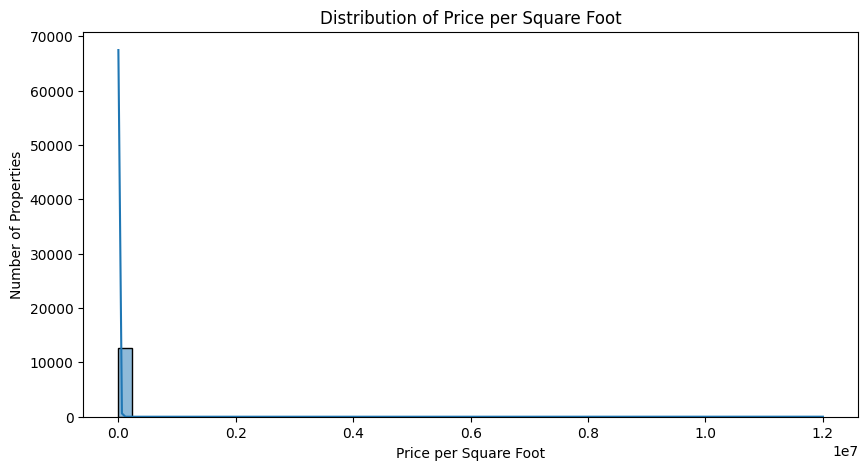

In [35]:
#visualize the price per sqft distribution

plt.figure(figsize=(10, 5))
sns.histplot(df_clean["price_per_sqft"], bins=50, kde=True)
plt.title("Distribution of Price per Square Foot")
plt.xlabel("Price per Square Foot")
plt.ylabel("Number of Properties")
plt.show()

In [38]:
# Inspect the relationship between area and bedrooms


# # Purpose: Identify properties with unusually small floor areas for their bedroom count.

df_clean["sqft_per_bhk"] = df_clean["total_sqft"] / df_clean["bhk"]

display(
    df_clean[["total_sqft", "bhk", "sqft_per_bhk"]].head(10)
)

,total_sqft,bhk,sqft_per_bhk
0,1056.0,2.0,528.000000
1,2600.0,4.0,650.000000
2,1440.0,3.0,480.000000
3,1521.0,3.0,507.000000
4,1200.0,2.0,600.000000
5,1170.0,2.0,585.000000
6,2732.0,4.0,683.000000
7,3300.0,4.0,825.000000
8,1310.0,3.0,436.666667
9,1020.0,6.0,170.000000


In [39]:
#identify suspicious area-to-bedroom records

suspicious_area = df_clean[df_clean["sqft_per_bhk"] < 300]

print("Properties below 300 sqft per bedroom:",
      len(suspicious_area))

display(suspicious_area.head(10))

Properties below 300 sqft per bedroom: 734


,area_type,availability,location,size,society,total_sqft,bath,balcony,price,bhk,price_per_sqft,sqft_per_bhk
9,Plot Area,Ready To Move,Gandhi Bazar,6 Bedroom,Unknown,1020.0,6.0,2.0,370.0,6.0,36274.509804,170.000000
45,Plot Area,Ready To Move,HSR Layout,8 Bedroom,Unknown,600.0,9.0,2.0,200.0,8.0,33333.333333,75.000000
58,Plot Area,Ready To Move,Murugeshpalya,6 Bedroom,Unknown,1407.0,4.0,1.0,150.0,6.0,10660.980810,234.500000
68,Plot Area,Ready To Move,Devarachikkanahalli,8 Bedroom,Unknown,1350.0,7.0,0.0,85.0,8.0,6296.296296,168.750000
70,Plot Area,Ready To Move,Double Road,3 Bedroom,Unknown,500.0,3.0,2.0,100.0,3.0,20000.000000,166.666667
78,Built-up Area,Ready To Move,Kaval Byrasandra,2 BHK,Unknown,460.0,1.0,0.0,22.0,2.0,4782.608696,230.000000
89,Plot Area,Ready To Move,Rajaji Nagar,6 Bedroom,Unknown,710.0,6.0,3.0,160.0,6.0,22535.211268,118.333333
119,Plot Area,Ready To Move,Hennur Road,2 Bedroom,Unknown,276.0,3.0,3.0,23.0,2.0,8333.333333,138.000000
129,Plot Area,Ready To Move,Vishwapriya Layout,7 Bedroom,Unknown,950.0,7.0,0.0,115.0,7.0,12105.263158,135.714286
149,Plot Area,Ready To Move,Dinnur,6 Bedroom,Unknown,1034.0,5.0,2.0,185.0,6.0,17891.682785,172.333333


In [40]:
#inspect bathroom conunts against bedroom counts

suspicious_bath = df_clean[
    df_clean["bath"] > df_clean["bhk"] + 2
]

print("Properties with unusually high bathroom counts:",
      len(suspicious_bath))

display(
    suspicious_bath[["size", "bhk", "bath", "total_sqft", "price"]].head(10)
)


Properties with unusually high bathroom counts: 16


,size,bhk,bath,total_sqft,price
1078,9 Bedroom,9.0,14.0,3300.0,500.0
1953,8 Bedroom,8.0,12.0,1200.0,110.0
1979,8 Bedroom,8.0,12.0,990.0,120.0
2620,6 BHK,6.0,9.0,11338.0,1000.0
6838,5 BHK,5.0,8.0,7500.0,1700.0
6937,9 Bedroom,9.0,12.0,2600.0,675.0
7709,4 Bedroom,4.0,7.0,2460.0,80.0
8106,8 Bedroom,8.0,12.0,1850.0,300.0
9974,3 Bedroom,3.0,6.0,2400.0,775.0
9990,6 Bedroom,6.0,9.0,1200.0,122.0


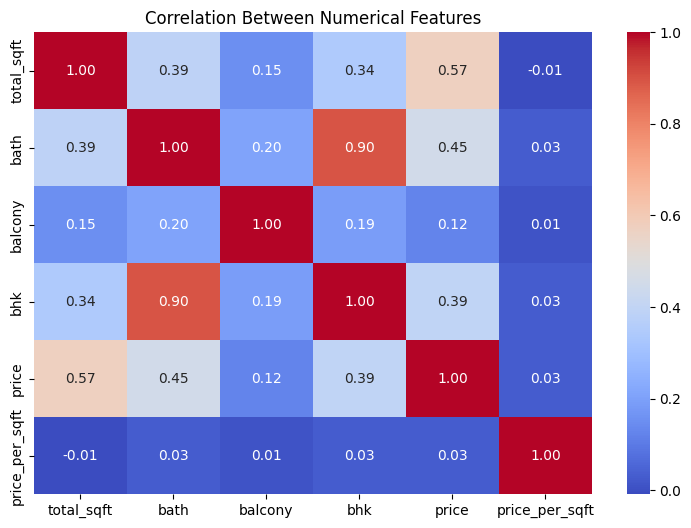

In [41]:
#check numerical correlations

numeric_cols = [
    "total_sqft",
    "bath",
    "balcony",
    "bhk",
    "price",
    "price_per_sqft"
]

correlation = df_clean[numeric_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(correlation, annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlation Between Numerical Features")
plt.show()

In [43]:
#save the work so far

# Create the destination directory if it doesn't exist
os.makedirs(processed_folder, exist_ok=True)

cleaned_file = os.path.join(
    processed_folder,
    "bengaluru_housing_cleaned_stage1.csv"
)

df_clean.to_csv(cleaned_file, index=False)

print("File saved:", cleaned_file)
print("Saved dataset shape:", df_clean.shape)
print("File exists:", os.path.exists(cleaned_file))

File saved: /content/drive/MyDrive/MVJ_Internship/Project3/Day17_Regression/data/processed/bengaluru_housing_cleaned_stage1.csv
Saved dataset shape: (12728, 12)
File exists: True


Prepare a machine learning dataset


In [44]:
#create a backup before outlier treatment

df_stage1 = df_clean.copy()

print("Stage 1 shape:", df_stage1.shape)
print("Backup created:", df_stage1.equals(df_clean))

Stage 1 shape: (12728, 12)
Backup created: True


In [45]:
#remove invalid numerical values

before = len(df_clean)

df_clean = df_clean[
    (df_clean["total_sqft"] > 0) &
    (df_clean["price"] > 0) &
    (df_clean["bhk"] > 0) &
    (df_clean["bath"] > 0)
].copy()

print("Rows before:", before)
print("Rows after:", len(df_clean))
print("Rows removed:", before - len(df_clean))

Rows before: 12728
Rows after: 12728
Rows removed: 0


In [46]:
#remove unusually low area-per-bedroom records

before = len(df_clean)

df_clean = df_clean[df_clean["sqft_per_bhk"] > 300].copy()

print("Rows removed:", before - len(df_clean))
print("Remaining rows:", len(df_clean))


Rows removed: 916
Remaining rows: 11812


In [47]:
#remove unusually high bathroom counts

before = len(df_clean)

df_clean = df_clean[
    df_clean["bath"] <= df_clean["bhk"] + 2
].copy()

print("Rows removed:", before - len(df_clean))
print("Remaining rows:", len(df_clean))

Rows removed: 9
Remaining rows: 11803


In [48]:
#inspect price-per-sqft percentiles again

print(
    df_clean["price_per_sqft"].describe(
        percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
    )
)

count     11803.000000
mean       6255.121133
std        4050.674521
min         267.829813
1%         2500.862833
5%         3098.161507
25%        4236.004379
50%        5299.224806
75%        6875.000000
95%       13029.598309
99%       20833.333333
max      176470.588235
Name: price_per_sqft, dtype: float64


In [49]:
#calculate the price per sqft IQR

Q1 = df_clean["price_per_sqft"].quantile(0.25)
Q3 = df_clean["price_per_sqft"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR
upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Lower limit:", lower_limit)
print("Upper limit:", upper_limit)

Q1: 4236.004378762999
Q3: 6875.0
IQR: 2638.9956212370007
Lower limit: 277.51094690749824
Upper limit: 10833.4934318555


In [50]:
#count potential price per sqft  outliers

outliers = df_clean[
    (df_clean["price_per_sqft"] < lower_limit) |
    (df_clean["price_per_sqft"] > upper_limit)
]

print("Potential outliers:", len(outliers))
print("Percentage of dataset:",
      round(len(outliers) / len(df_clean) * 100, 2), "%")

Potential outliers: 924
Percentage of dataset: 7.83 %


In [51]:
#filter extreme price per sqft foot values

before = len(df_clean)

df_clean = df_clean[
    (df_clean["price_per_sqft"] >= lower_limit) &
    (df_clean["price_per_sqft"] <= upper_limit)
].copy()

print("Rows before:", before)
print("Rows after:", len(df_clean))
print("Rows removed:", before - len(df_clean))

Rows before: 11803
Rows after: 10879
Rows removed: 924


In [52]:
#verify the filtered dataset

print("Remaining rows:", len(df_clean))
print("Minimum price per sqft:", df_clean["price_per_sqft"].min())
print("Maximum price per sqft:", df_clean["price_per_sqft"].max())

remaining_outliers = df_clean[
    (df_clean["price_per_sqft"] < lower_limit) |
    (df_clean["price_per_sqft"] > upper_limit)
]

print("Remaining IQR outliers:", len(remaining_outliers))

Remaining rows: 10879
Minimum price per sqft: 371.42857142857144
Maximum price per sqft: 10833.333333333334
Remaining IQR outliers: 0


In [53]:
# Save the outlier-treated data separately

stage2_file = os.path.join(
    processed_folder,
    "bengaluru_housing_cleaned_stage2.csv"
)

df_clean.to_csv(stage2_file, index=False)

print("File saved:", os.path.exists(stage2_file))
print("Dataset shape:", df_clean.shape)

File saved: True
Dataset shape: (10879, 12)


In [54]:
#check the most common locations

location_counts = df_clean["location"].value_counts()

display(location_counts.head(15).to_frame("Property Count"))

,Property Count
location,
Whitefield,480
Sarjapur Road,357
Electronic City,276
Kanakpura Road,245
Thanisandra,225
Yelahanka,202
Marathahalli,161
Raja Rajeshwari Nagar,154
Hebbal,149


In [55]:
#group locations with very few records

location_counts = df_clean["location"].value_counts()

df_clean["location_model"] = df_clean["location"].apply(
    lambda x: x if location_counts[x] >= 10 else "Other"
)

print("Original unique locations:",
      df_clean["location"].nunique())

print("Model locations:",
      df_clean["location_model"].nunique())

print("\nMost common model locations:")
display(df_clean["location_model"].value_counts().head(15))

Original unique locations: 1100
Model locations: 209

Most common model locations:


,count
location_model,
Other,2299
Whitefield,480
Sarjapur Road,357
Electronic City,276
Kanakpura Road,245
Thanisandra,225
Yelahanka,202
Marathahalli,161
Raja Rajeshwari Nagar,154


In [56]:
#remove unnecessary columns for modelling

columns_to_drop = [
    "size",
    "society",
    "availability",
    "location",
    "price_per_sqft",
    "sqft_per_bhk"
]

df_model = df_clean.drop(
    columns=columns_to_drop,
    errors="ignore"
).copy()

print("Model dataset shape:", df_model.shape)
print("\nRemaining columns:")
print(df_model.columns.tolist())

Model dataset shape: (10879, 7)

Remaining columns:
['area_type', 'total_sqft', 'bath', 'balcony', 'price', 'bhk', 'location_model']


In [57]:
# Separate features and target
# Brief: Separate the information used to predict the house price from the price itself.

X = df_model.drop("price", axis=1)
y = df_model["price"]

print("Feature dataset shape:", X.shape)
print("Target dataset shape:", y.shape)

print("\nFeatures:")
print(X.columns.tolist())

print("\nTarget preview:")
display(y.head())

Feature dataset shape: (10879, 6)
Target dataset shape: (10879,)

Features:
['area_type', 'total_sqft', 'bath', 'balcony', 'bhk', 'location_model']

Target preview:


,price
0,39.07
1,120.00
2,62.00
3,95.00
4,51.00


In [58]:
#split the daataset into training and testing sets

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (8703, 6)
Testing features: (2176, 6)
Training target: (8703,)
Testing target: (2176,)


Model Building

In [59]:
#identify categorical and numerical columns

categorical_cols = X_train.select_dtypes(
    include=["object"]
).columns.tolist()

numerical_cols = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['area_type', 'location_model']
Numerical columns: ['total_sqft', 'bath', 'balcony', 'bhk']


In [60]:
#check missing values in training and testing data

print("Missing values in X_train:")
print(X_train.isnull().sum())

print("\nMissing values in X_test:")
print(X_test.isnull().sum())

print("\nMissing values in y_train:", y_train.isnull().sum())
print("Missing values in y_test:", y_test.isnull().sum())

Missing values in X_train:
area_type         0
total_sqft        0
bath              0
balcony           0
bhk               0
location_model    0
dtype: int64

Missing values in X_test:
area_type         0
total_sqft        0
bath              0
balcony           0
bhk               0
location_model    0
dtype: int64

Missing values in y_train: 0
Missing values in y_test: 0


In [61]:
#import preprocessing tools

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

In [62]:
#build the preprocessing pipeline

preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore"),
         categorical_cols),

        ("numerical", StandardScaler(),
         numerical_cols)
    ]
)

print("Preprocessing pipeline created.")

Preprocessing pipeline created.


In [63]:
#transform the training and testing features

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed testing shape:", X_test_processed.shape)

Processed training shape: (8703, 217)
Processed testing shape: (2176, 217)


In [66]:
#import regression and evaluation metricx

from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Regression model and evaluation metrics imported.")

Regression model and evaluation metrics imported.


In [67]:
#create the linear regression model

model = LinearRegression()

print("Linear Regression model created.")

Linear Regression model created.


In [68]:
model.fit(X_train_processed, y_train)

print("Model training completed.")

Model training completed.


In [69]:
# Use the trained model to predict prices for the unseen testing dataset.

y_pred = model.predict(X_test_processed)

print("First 10 actual prices:")
print(y_test.head(10).values)

print("\nFirst 10 predicted prices:")
print(y_pred[:10])

First 10 actual prices:
[ 86.    75.    55.   123.    79.   142.    34.98  64.08  64.08  45.5 ]

First 10 predicted prices:
[ 58.34299993  85.47009467  68.46583542  88.11422709  65.41448209
 126.47855598  42.50710852  76.32280345  76.44303364  47.28664438]


In [70]:
#calculate mean absolute error

mae = mean_absolute_error(y_test, y_pred)

print("Mean Absolute Error:", round(mae, 2))

Mean Absolute Error: 22.14


In [71]:
# Calculate Mean Squared Error and Root Mean Squared Error

mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)

print("Mean Squared Error:", round(mse, 2))
print("Root Mean Squared Error:", round(rmse, 2))

Mean Squared Error: 1581.26
Root Mean Squared Error: 39.77


In [72]:
# Calculate the R² score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", round(r2, 4))

R2 Score: 0.6137


In [73]:
#display all evaluation metrics together

model_results = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Value": [mae, mse, rmse, r2]
})

display(model_results)

,Metric,Value
0,MAE,22.137217
1,MSE,1581.257601
2,RMSE,39.765030
3,R2 Score,0.613747


In [74]:
#compare actual and predicted prices

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

comparison["Difference"] = (
    comparison["Actual Price"] - comparison["Predicted Price"]
)

display(comparison.head(15))

,Actual Price,Predicted Price,Difference
0,86.00,58.343000,27.657000
1,75.00,85.470095,-10.470095
2,55.00,68.465835,-13.465835
3,123.00,88.114227,34.885773
4,79.00,65.414482,13.585518
5,142.00,126.478556,15.521444
6,34.98,42.507109,-7.527109
7,64.08,76.322803,-12.242803
8,64.08,76.443034,-12.363034
9,45.50,47.286644,-1.786644


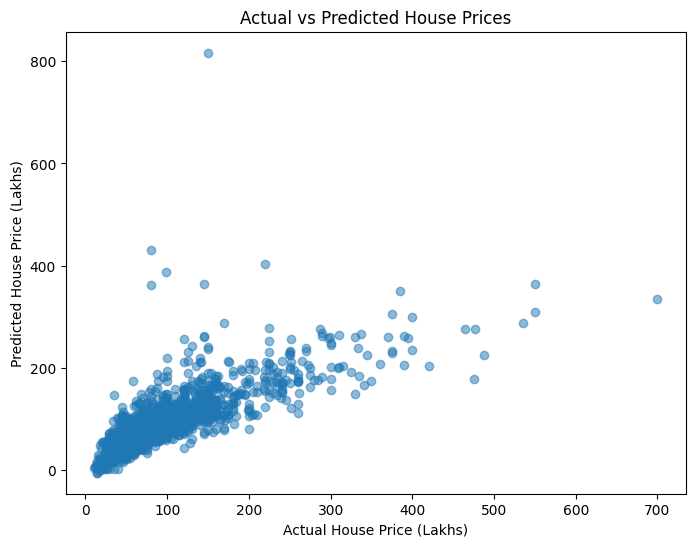

In [75]:
#plot the actual vs predicted prices table

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.5)

plt.xlabel("Actual House Price (Lakhs)")
plt.ylabel("Predicted House Price (Lakhs)")
plt.title("Actual vs Predicted House Prices")

plt.show()

In [76]:
#save the trained model and preprocessing pipeline

import joblib

model_file = os.path.join(
    processed_folder,
    "bengaluru_house_price_model.pkl"
)

preprocessor_file = os.path.join(
    processed_folder,
    "bengaluru_house_price_preprocessor.pkl"
)

joblib.dump(model, model_file)
joblib.dump(preprocessor, preprocessor_file)

print("Model saved:", os.path.exists(model_file))
print("Preprocessor saved:", os.path.exists(preprocessor_file))

Model saved: True
Preprocessor saved: True


FINAL VALIDATIONS

In [77]:
import joblib

loaded_model = joblib.load(model_file)
loaded_preprocessor = joblib.load(preprocessor_file)

print("Model loaded:", loaded_model is not None)
print("Preprocessor loaded:", loaded_preprocessor is not None)

Model loaded: True
Preprocessor loaded: True


In [78]:
#TEST PREDICTIONS USING THE SAVED FILES
X_test_reloaded = loaded_preprocessor.transform(X_test)
reloaded_predictions = loaded_model.predict(X_test_reloaded)

print("Predictions generated:", len(reloaded_predictions))
print("First 5 predictions:", reloaded_predictions[:5])


Predictions generated: 2176
First 5 predictions: [58.34299993 85.47009467 68.46583542 88.11422709 65.41448209]


In [79]:
#CALCULATE PREDICTION ERRORS
final_predictions = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": reloaded_predictions
})

final_predictions["Error"] = (
    final_predictions["Actual_Price"] -
    final_predictions["Predicted_Price"]
)

final_predictions["Absolute_Error"] = (
    final_predictions["Error"].abs()
)

display(final_predictions.head(10))

,Actual_Price,Predicted_Price,Error,Absolute_Error
0,86.00,58.343000,27.657000,27.657000
1,75.00,85.470095,-10.470095,10.470095
2,55.00,68.465835,-13.465835,13.465835
3,123.00,88.114227,34.885773,34.885773
4,79.00,65.414482,13.585518,13.585518
5,142.00,126.478556,15.521444,15.521444
6,34.98,42.507109,-7.527109,7.527109
7,64.08,76.322803,-12.242803,12.242803
8,64.08,76.443034,-12.363034,12.363034
9,45.50,47.286644,-1.786644,1.786644


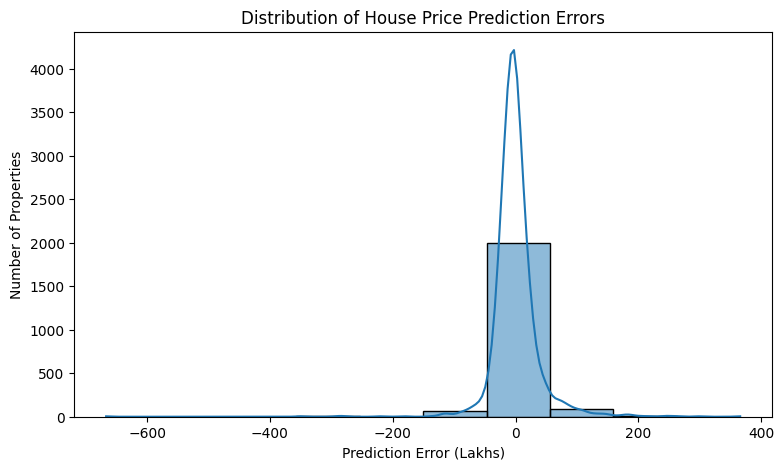

In [86]:
#visualize prediction errors

plt.figure(figsize=(9,5))

sns.histplot(
    final_predictions["Error"],
    bins=10,
    kde=True
)

plt.title("Distribution of House Price Prediction Errors")
plt.xlabel("Prediction Error (Lakhs)")
plt.ylabel("Number of Properties")

plt.show()

In [87]:
#save the prediction resilts

prediction_file = os.path.join(
    processed_folder,
    "bengaluru_house_price_predictions.csv"
)

final_predictions.to_csv(prediction_file, index=False)

print("Predictions saved:", os.path.exists(prediction_file))
print("Total prediction records:", len(final_predictions))

Predictions saved: True
Total prediction records: 2176


In [88]:
#save the model evaluation report

evaluation_report = pd.DataFrame({
    "Metric": ["MAE", "MSE", "RMSE", "R2 Score"],
    "Value": [
        mean_absolute_error(y_test, reloaded_predictions),
        mean_squared_error(y_test, reloaded_predictions),
        np.sqrt(mean_squared_error(y_test, reloaded_predictions)),
        r2_score(y_test, reloaded_predictions)
    ]
})

report_file = os.path.join(
    processed_folder,
    "bengaluru_house_price_evaluation.csv"
)

evaluation_report.to_csv(report_file, index=False)

display(evaluation_report)

print("Evaluation report saved:", os.path.exists(report_file))

,Metric,Value
0,MAE,22.137217
1,MSE,1581.257601
2,RMSE,39.765030
3,R2 Score,0.613747


Evaluation report saved: True


In [89]:
#perform final project validation

required_files = [
    stage2_file,
    model_file,
    preprocessor_file,
    prediction_file,
    report_file
]

print("FINAL PROJECT VALIDATION")

for file in required_files:
    print(os.path.basename(file), ":", os.path.exists(file))

print("\nPrediction records:", len(final_predictions))
print("Missing prediction values:",
      final_predictions.isnull().sum().sum())

print("Infinite prediction values:",
      np.isinf(final_predictions.select_dtypes(include="number")).sum().sum())

FINAL PROJECT VALIDATION
bengaluru_housing_cleaned_stage2.csv : True
bengaluru_house_price_model.pkl : True
bengaluru_house_price_preprocessor.pkl : True
bengaluru_house_price_predictions.csv : True
bengaluru_house_price_evaluation.csv : True

Prediction records: 2176
Missing prediction values: 0
Infinite prediction values: 0


In [90]:
#create a day 17 summary

summary = f"""
DAY 17 - BENGALURU HOUSE PRICE REGRESSION

Project: Bengaluru House Price Prediction

Dataset:
Original cleaned dataset rows: {len(df)}
Final modelling dataset rows: {len(df_model)}

Model:
Algorithm: Linear Regression
Training records: {len(X_train)}
Testing records: {len(X_test)}

Evaluation Metrics:
MAE: {mae:.4f}
MSE: {mse:.4f}
RMSE: {rmse:.4f}
R2 Score: {r2:.4f}

Completed Tasks:
1. Dataset inspection
2. Data cleaning
3. Missing value treatment
4. Feature creation
5. Outlier detection and treatment
6. Categorical encoding
7. Feature scaling
8. Train-test splitting
9. Linear Regression model training
10. Model evaluation
11. Prediction generation
12. Model and result saving

Status: Completed
"""

summary_file = os.path.join(
    project_folder,
    "Day17_Project_Summary.txt"
)

with open(summary_file, "w") as file:
    file.write(summary)

print("Project summary saved:", os.path.exists(summary_file))

Project summary saved: True


In [91]:
#check the final project folder

print("PROCESSED FOLDER CONTENTS")

for file in sorted(os.listdir(processed_folder)):
    print("-", file)

print("\nPROJECT SUMMARY:")
print(summary_file)

PROCESSED FOLDER CONTENTS
- bengaluru_house_price_evaluation.csv
- bengaluru_house_price_model.pkl
- bengaluru_house_price_predictions.csv
- bengaluru_house_price_preprocessor.pkl
- bengaluru_housing_cleaned_stage1.csv
- bengaluru_housing_cleaned_stage2.csv

PROJECT SUMMARY:
/content/drive/MyDrive/MVJ_Internship/Project3/Day17_Regression/Day17_Project_Summary.txt
